In [ ]:
from google.colab import files

uploaded = files.upload()

Saving Iris.csv to Iris (1).csv


In [ ]:
import pandas as pd

df = pd.read_csv("Iris.csv")

df.head()

,Id,SepalLengthCm,SepalWidthCm,PetalLengthCm,PetalWidthCm,Species
0,1,5.1,3.5,1.4,0.2,Iris-setosa
1,2,4.9,3.0,1.4,0.2,Iris-setosa
2,3,4.7,3.2,1.3,0.2,Iris-setosa
3,4,4.6,3.1,1.5,0.2,Iris-setosa
4,5,5.0,3.6,1.4,0.2,Iris-setosa


In [ ]:
print("Number of records:", df.shape[0])
print("Number of columns:", df.shape[1])

print("\nColumn names:")
print(df.columns)

print("\nData types:")
print(df.dtypes)

In [ ]:
df.describe()

In [ ]:
import numpy as np

features = ["SepalLengthCm", "SepalWidthCm",
            "PetalLengthCm", "PetalWidthCm"]

for feature in features:
    print("\n", feature)
    print("Mean:", np.mean(df[feature]))
    print("Minimum:", np.min(df[feature]))
    print("Maximum:", np.max(df[feature]))
    print("Standard Deviation:", np.std(df[feature]))

In [ ]:
selected_data = df[["SepalLengthCm", "SepalWidthCm",
                    "PetalLengthCm", "PetalWidthCm",
                    "Species"]]

selected_data.head()

In [ ]:
setosa = df[df["Species"] == "Iris-setosa"]

setosa.head()



In [ ]:
grouped = df.groupby("Species")[features].mean()

grouped
summary = df.groupby("Species")[features].agg(
    ["mean", "min", "max", "std"]
)

summary

In [ ]:
import matplotlib.pyplot as plt
plt.figure(figsize=(8, 6))

for species in df["Species"].unique():
    data = df[df["Species"] == species]
    plt.scatter(data["SepalLengthCm"],
                data["SepalWidthCm"],
                label=species)

plt.xlabel("Sepal Length (cm)")
plt.ylabel("Sepal Width (cm)")
plt.title("Sepal Length vs Sepal Width")
plt.legend()
plt.show()

In [ ]:
plt.figure(figsize=(8, 6))

for species in df["Species"].unique():
    data = df[df["Species"] == species]
    plt.scatter(data["PetalLengthCm"],
                data["PetalWidthCm"],
                label=species)

plt.xlabel("Petal Length (cm)")
plt.ylabel("Petal Width (cm)")
plt.title("Petal Length vs Petal Width")
plt.legend()
plt.show()

In [ ]:
df[features].hist(figsize=(10, 8))

plt.suptitle("Distribution of Iris Features")
plt.show()

In [ ]:
plt.figure(figsize=(10, 6))

df.boxplot(column="PetalLengthCm", by="Species")

plt.title("Petal Length Distribution by Iris Class")
plt.suptitle("")
plt.xlabel("Iris Species")
plt.ylabel("Petal Length (cm)")
plt.show()

In [ ]:
print("Average measurements for each Iris class:")
print(grouped)

print("\nMost useful features can be compared using these averages.")

In [ ]:
grouped.plot(kind="bar", figsize=(10, 6))

plt.title("Average Feature Values by Iris Class")
plt.xlabel("Iris Species")
plt.ylabel("Average Measurement (cm)")
plt.xticks(rotation=0)
plt.legend(title="Features")
plt.show()
correlation = df[features].corr()

print("Correlation between features:")
print(correlation)

plt.figure(figsize=(8, 6))

plt.imshow(correlation)
plt.colorbar()

plt.xticks(range(len(features)), features, rotation=45)
plt.yticks(range(len(features)), features)

plt.title("Correlation Between Iris Features")

plt.show()

QUESTION 2: Supervised and Unsupervised Learning Using Iris Dataset


In [ ]:
import pandas as pd

df = pd.read_csv("Iris.csv")

print("Dataset loaded successfully!")
print(df.head())

Dataset loaded successfully!
   Id  SepalLengthCm  SepalWidthCm  PetalLengthCm  PetalWidthCm      Species
0   1            5.1           3.5            1.4           0.2  Iris-setosa
1   2            4.9           3.0            1.4           0.2  Iris-setosa
2   3            4.7           3.2            1.3           0.2  Iris-setosa
3   4            4.6           3.1            1.5           0.2  Iris-setosa
4   5            5.0           3.6            1.4           0.2  Iris-setosa


In [ ]:
from google.colab import files

uploaded = files.upload()

KeyboardInterrupt: 

In [ ]:
features = ["SepalLengthCm", "SepalWidthCm",
            "PetalLengthCm", "PetalWidthCm"]

X = df[features]
y = df["Species"]

print("Input Features:")
print(features)

print("\nTarget Variable:")
print("Species")

Input Features:
['SepalLengthCm', 'SepalWidthCm', 'PetalLengthCm', 'PetalWidthCm']

Target Variable:
Species


In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, confusion_matrix

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print("Training records:", len(X_train))
print("Testing records:", len(X_test))

Training records: 120
Testing records: 30


In [ ]:
model = KNeighborsClassifier(n_neighbors=5)

model.fit(X_train, y_train)

print("KNN model trained successfully.")

KNN model trained successfully.


In [ ]:
y_pred = model.predict(X_test)

print("Predicted Classes:")
print(y_pred)

Predicted Classes:
['Iris-versicolor' 'Iris-setosa' 'Iris-virginica' 'Iris-versicolor'
 'Iris-versicolor' 'Iris-setosa' 'Iris-versicolor' 'Iris-virginica'
 'Iris-versicolor' 'Iris-versicolor' 'Iris-virginica' 'Iris-setosa'
 'Iris-setosa' 'Iris-setosa' 'Iris-setosa' 'Iris-versicolor'
 'Iris-virginica' 'Iris-versicolor' 'Iris-versicolor' 'Iris-virginica'
 'Iris-setosa' 'Iris-virginica' 'Iris-setosa' 'Iris-virginica'
 'Iris-virginica' 'Iris-virginica' 'Iris-virginica' 'Iris-virginica'
 'Iris-setosa' 'Iris-setosa']


In [ ]:
accuracy = accuracy_score(y_test, y_pred)

print("Model Accuracy:", accuracy)
print("Accuracy Percentage:", accuracy * 100, "%")

Model Accuracy: 1.0
Accuracy Percentage: 100.0 %


In [ ]:
cm = confusion_matrix(y_test, y_pred)

print("Confusion Matrix:")
print(cm)

Confusion Matrix:
[[10  0  0]
 [ 0  9  0]
 [ 0  0 11]]


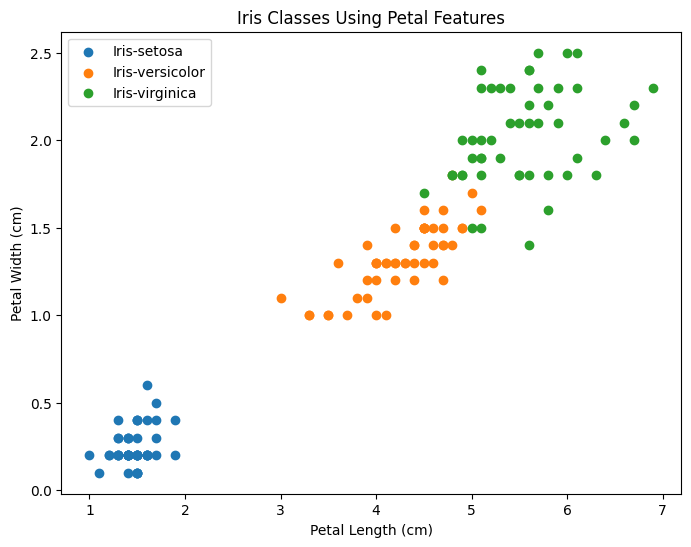

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 6))

for species in df["Species"].unique():
    data = df[df["Species"] == species]

    plt.scatter(
        data["PetalLengthCm"],
        data["PetalWidthCm"],
        label=species
    )

plt.xlabel("Petal Length (cm)")
plt.ylabel("Petal Width (cm)")
plt.title("Iris Classes Using Petal Features")
plt.legend()
plt.show()

In [ ]:
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler

In [ ]:
X_cluster = df[features]

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_cluster)

print("Data prepared for clustering.")

Data prepared for clustering.


In [ ]:
kmeans = KMeans(n_clusters=3, random_state=42, n_init=10)

clusters = kmeans.fit_predict(X_scaled)

print("Cluster labels:")
print(clusters)

Cluster labels:
[1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1
 1 1 1 1 1 1 1 1 1 1 1 1 1 2 2 2 0 0 0 2 0 0 0 0 0 0 0 0 2 0 0 0 0 2 0 0 0
 0 2 2 2 0 0 0 0 0 0 0 2 2 0 0 0 0 0 0 0 0 0 0 0 0 0 2 0 2 2 2 2 0 2 2 2 2
 2 2 0 0 2 2 2 2 0 2 0 2 0 2 2 0 2 2 2 2 2 2 0 0 2 2 2 0 2 2 2 0 2 2 2 0 2
 2 0]


In [ ]:
df["Cluster"] = clusters

print(df[features + ["Cluster"]].head(10))

   SepalLengthCm  SepalWidthCm  PetalLengthCm  PetalWidthCm  Cluster
0            5.1           3.5            1.4           0.2        1
1            4.9           3.0            1.4           0.2        1
2            4.7           3.2            1.3           0.2        1
3            4.6           3.1            1.5           0.2        1
4            5.0           3.6            1.4           0.2        1
5            5.4           3.9            1.7           0.4        1
6            4.6           3.4            1.4           0.3        1
7            5.0           3.4            1.5           0.2        1
8            4.4           2.9            1.4           0.2        1
9            4.9           3.1            1.5           0.1        1


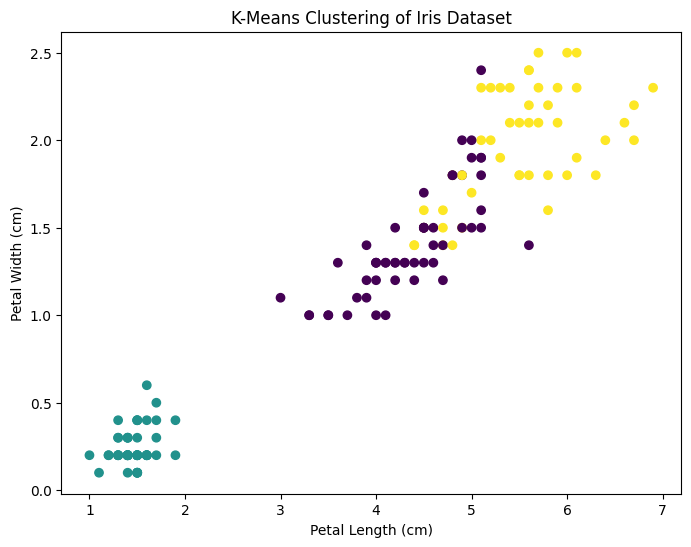

In [ ]:
plt.figure(figsize=(8, 6))

plt.scatter(
    df["PetalLengthCm"],
    df["PetalWidthCm"],
    c=df["Cluster"]
)

plt.xlabel("Petal Length (cm)")
plt.ylabel("Petal Width (cm)")
plt.title("K-Means Clustering of Iris Dataset")
plt.show()

In [ ]:
comparison = pd.crosstab(df["Cluster"], df["Species"])

print("Comparison of Clusters and Actual Species:")
print(comparison)

Comparison of Clusters and Actual Species:
Species  Iris-setosa  Iris-versicolor  Iris-virginica
Cluster                                              
0                  0               39              14
1                 50                0               0
2                  0               11              36


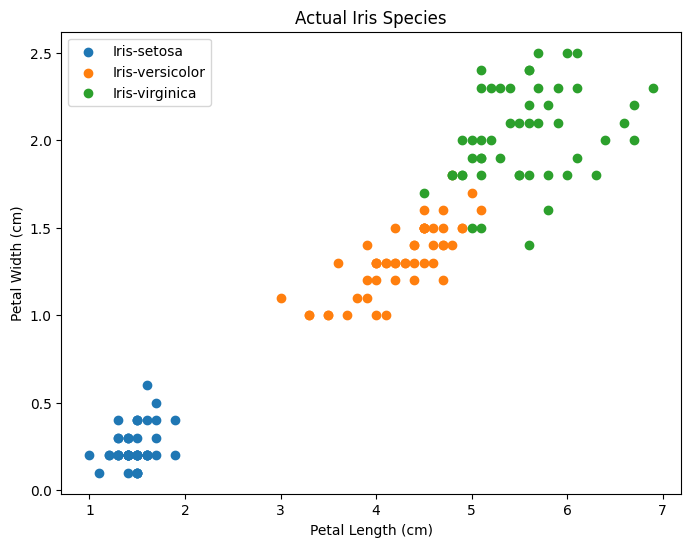

In [ ]:
plt.figure(figsize=(8, 6))

for species in df["Species"].unique():
    data = df[df["Species"] == species]

    plt.scatter(
        data["PetalLengthCm"],
        data["PetalWidthCm"],
        label=species
    )

plt.xlabel("Petal Length (cm)")
plt.ylabel("Petal Width (cm)")
plt.title("Actual Iris Species")
plt.legend()
plt.show()

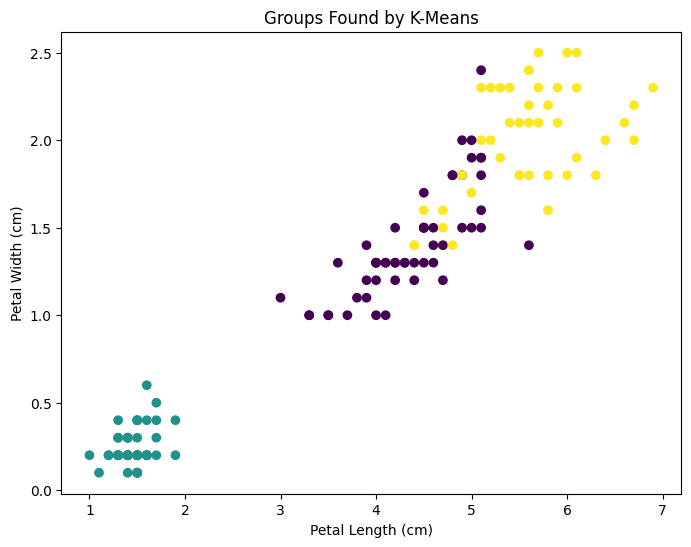

In [ ]:
plt.figure(figsize=(8, 6))

plt.scatter(
    df["PetalLengthCm"],
    df["PetalWidthCm"],
    c=df["Cluster"]
)

plt.xlabel("Petal Length (cm)")
plt.ylabel("Petal Width (cm)")
plt.title("Groups Found by K-Means")
plt.show()